# Workflow

move(x, y) -> stage(z) using hill climbing -> defocus using hill climbing -> A1 using hill climbing -> get overview image (haadf) -> get EDS

In [2]:
%matplotlib widget

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import tango
from IPython.display import clear_output, display
from tiled.client import from_uri

TANGO_DATABASE_HOST = "10.46.217.241"
# TANGO_DATABASE_HOST = "localhost"
TANGO_DATABASE_PORT = 9094
os.environ["TANGO_HOST"] = f"{TANGO_DATABASE_HOST}:{TANGO_DATABASE_PORT}"

scan = tango.DeviceProxy("asyncroscopy/scan/default")
microscope = tango.DeviceProxy("asyncroscopy/instrument/default")
stage = tango.DeviceProxy("asyncroscopy/stage/default")
data = tango.DeviceProxy("asyncroscopy/data/default")
corrector = tango.DeviceProxy("asyncroscopy/corrector/default")


for proxy in (scan, microscope, stage, data):
    proxy.set_timeout_millis(120_000)
    proxy.ping()
    print(proxy.name(), proxy.state())

tiled_config = json.loads(data.get_config())
client = from_uri(tiled_config["uri"])
print("Tiled:", tiled_config["uri"])
print(f"Current stage.z: {float(stage.z) * 1e6:+.6f} µm")

asyncroscopy/scan/default ON
asyncroscopy/instrument/default ON
asyncroscopy/stage/default ON
asyncroscopy/data/default ON
Tiled: http://10.46.217.241:9091
Current stage.z: -112.498830 µm


## common utilities 

In [3]:
def read_haadf(key):
    node = client[key]
    if "image" in node:
        node = node["image"]
    if "HAADF" in node:
        node = node["HAADF"]
    return np.asarray(node.read(), dtype=np.float64)

def contrast(image):
    image = np.asarray(image, dtype=np.float64)
    low, high = np.percentile(image, [1, 99])
    clipped = np.clip(image, low, high)
    return float(np.std(clipped) / (abs(np.mean(clipped)) + 1e-12))



## utilites for hill climbing in z height

In [4]:
# Options: "contrast", "edge_sharpness"
OPTIMIZATION_METRIC = "contrast"
METRIC_NAMES = ("contrast", "edge_sharpness")

scan.imsize = 512
scan.dwell_time = 2e-6
scan.scan_region = [0, 0, 1, 1]

def edge_sharpness(image):
    image = np.asarray(image, dtype=np.float64)
    low, high = np.percentile(image, [1, 99])
    clipped = np.clip(image, low, high)
    normalized = clipped / (abs(np.mean(clipped)) + 1e-12)
    gradient_y, gradient_x = np.gradient(normalized)
    return float(np.sqrt(np.mean(gradient_x * gradient_x + gradient_y * gradient_y)))

def acquire_and_measure_z():
    key = microscope.acquire_scanned_image(["HAADF"])
    image = read_haadf(key)
    metrics = {"contrast": contrast(image), "edge_sharpness": edge_sharpness(image)}
    return metrics, key, image

def optimization_score_z(metrics):
    if OPTIMIZATION_METRIC not in METRIC_NAMES:
        raise ValueError(f"OPTIMIZATION_METRIC must be one of {METRIC_NAMES}")
    return metrics[OPTIMIZATION_METRIC]

def fit_response(history):
    z_m = np.asarray([item["stage_z_m"] for item in history])
    scores = np.asarray([item[OPTIMIZATION_METRIC] for item in history])
    center = z_m.mean()
    scale = max(z_m.std(), 1e-12)
    x = (z_m - center) / scale
    design = np.column_stack([np.ones(len(x)), x, x * x])
    ridge = 1e-6 * np.eye(design.shape[1])
    coefficients = np.linalg.solve(design.T @ design + ridge, design.T @ scores)

    def predict(candidate_z_m):
        candidate = np.atleast_1d(candidate_z_m)
        x = (candidate - center) / scale
        return np.column_stack([np.ones(len(x)), x, x * x]) @ coefficients

    return predict

def propose_next_z(history, trust_radius_m, starting_z_m, max_offset_m):
    measured_z = np.asarray([item["stage_z_m"] for item in history])
    scores = np.asarray([item[OPTIMIZATION_METRIC] for item in history])
    best_z = measured_z[int(np.argmax(scores))]
    lower = max(best_z - trust_radius_m, starting_z_m - max_offset_m)
    upper = min(best_z + trust_radius_m, starting_z_m + max_offset_m)
    candidates = np.linspace(lower, upper, 401)
    separation = np.min(np.abs(candidates[:, None] - measured_z[None, :]), axis=1)
    candidates = candidates[separation > max(trust_radius_m / 40, 1e-12)]
    if not len(candidates):
        return None
    predict = fit_response(history)
    return float(candidates[int(np.argmax(predict(candidates)))])

def show_progress_z(history, image, key, starting_z_m, trust_radius_m):
    clear_output(wait=True)
    z_m = np.asarray([item["stage_z_m"] for item in history])
    scores = np.asarray([item[OPTIMIZATION_METRIC] for item in history])
    offsets_nm = (z_m - starting_z_m) * 1e9
    best_index = int(np.argmax(scores))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title(f"{key}\noptimizing {OPTIMIZATION_METRIC.upper()}")
    axes[0].axis("off")

    colors = {"contrast": "tab:orange", "edge_sharpness": "tab:blue"}
    for metric in METRIC_NAMES:
        values = np.asarray([item[metric] for item in history])
        active = metric == OPTIMIZATION_METRIC
        label = f"{metric}{'  ← optimizing' if active else ''}"
        axes[1].plot(values / (values[0] + 1e-12), marker="o", color=colors[metric], linewidth=2.8 if active else 1.2, label=label)
    axes[1].axhline(1, color="0.7", linewidth=0.8)
    axes[1].set(xlabel="acquisition", ylabel="relative to baseline", title="metric history")
    axes[1].legend(frameon=False, fontsize=8)
    axes[1].grid(alpha=0.2)

    margin = max(np.ptp(offsets_nm) * 0.2, trust_radius_m * 1e9, 1.0)
    grid_nm = np.linspace(offsets_nm.min() - margin, offsets_nm.max() + margin, 500)
    if len(history) >= 3:
        predict = fit_response(history)
        axes[2].plot(grid_nm, predict(starting_z_m + grid_nm * 1e-9), color="tab:blue", linewidth=2, label="quadratic fit")
    axes[2].plot(offsets_nm, scores, color="0.7", linewidth=0.8)
    axes[2].scatter(offsets_nm, scores, c=scores, cmap="viridis", edgecolor="white", s=60, zorder=3)
    axes[2].scatter(offsets_nm[best_index], scores[best_index], marker="*", s=190, color="tab:red", label="best")
    axes[2].set(xlabel="stage.z offset from start (nm)", ylabel=OPTIMIZATION_METRIC, title=f"{OPTIMIZATION_METRIC} vs stage.z")
    axes[2].legend(frameon=False)
    axes[2].grid(alpha=0.2)

    best_z_um = z_m[best_index] * 1e6
    fig.suptitle(f"best stage.z = {best_z_um:+.6f} µm  |  offset = {offsets_nm[best_index]:+.2f} nm")
    display(fig)
    plt.close(fig)

def hill_climb_stage_z(step_size_m, max_iterations=8, min_step_size_m=None, max_offset_m=2e-6):
    """One-dimensional quadratic response search using every measured point."""
    step = float(step_size_m)
    min_step = float(min_step_size_m if min_step_size_m is not None else step / 16)
    max_offset = float(max_offset_m)
    starting_z = float(stage.z)
    trust_radius = step
    history = []
    completed = False

    if step <= 0 or max_offset <= 0:
        raise ValueError("Step size and maximum offset must be positive")
    if step > max_offset:
        raise ValueError("Z_STEP_SIZE must not exceed MAX_Z_OFFSET")

    def measure_at(target_z, trial):
        lower = starting_z - max_offset
        upper = starting_z + max_offset
        if not lower <= target_z <= upper:
            raise ValueError("Proposed stage Z exceeds MAX_Z_OFFSET")
        stage.z = float(target_z)
        actual_z = float(stage.z)
        metrics, key, image = acquire_and_measure_z()
        history.append({**metrics, "key": key, "trial": trial, "stage_z_m": actual_z})
        show_progress_z(history, image, key, starting_z, trust_radius)
        return metrics

    try:
        measure_at(starting_z, "baseline")
        measure_at(starting_z - step, "initial -")
        measure_at(starting_z + step, "initial +")

        for iteration in range(max_iterations):
            previous_best = max(item[OPTIMIZATION_METRIC] for item in history)
            proposal = propose_next_z(history, trust_radius, starting_z, max_offset)
            if proposal is None:
                break
            metrics = measure_at(proposal, f"model {iteration}")
            if optimization_score_z(metrics) > previous_best * 1.001:
                trust_radius = min(trust_radius * 1.20, step * 2, max_offset)
            else:
                trust_radius *= 0.65
            if trust_radius < min_step:
                break

        best_index = int(np.argmax([item[OPTIMIZATION_METRIC] for item in history]))
        best = history[best_index]
        stage.z = float(best["stage_z_m"])
        final_z = float(stage.z)
        completed = True
    finally:
        if not completed:
            stage.z = starting_z
            print(f"Run did not complete; restored stage.z to {starting_z * 1e6:+.6f} µm")

    best_image = read_haadf(best["key"])
    show_progress_z(history, best_image, best["key"], starting_z, trust_radius)
    print(f"Stage Z complete; optimized {OPTIMIZATION_METRIC}: {best[OPTIMIZATION_METRIC]:.6g}")
    print(", ".join(f"{metric}={best[metric]:.6g}" for metric in METRIC_NAMES))
    print(f"start={starting_z * 1e6:+.6f} µm, final={final_z * 1e6:+.6f} µm, offset={(final_z - starting_z) * 1e9:+.3f} nm")
    return {"start_z_m": starting_z, "final_z_m": final_z, "optimized_metric": OPTIMIZATION_METRIC, "metrics": {metric: best[metric] for metric in METRIC_NAMES}, "key": best["key"], "history": history}

## utilities for hill climbing in aberration

In [5]:
# Select which metric drives the hill climb.
# Options: "contrast", "entropy", "high_frequency_power"
OPTIMIZATION_METRIC = "contrast"

# Shared acquisition settings
scan.imsize = 512
scan.dwell_time = 2e-6
scan.scan_region = [0, 0, 1, 1]


def entropy(image, bins=256):
    low, high = np.percentile(image, [1, 99])
    if high <= low:
        return 0.0
    histogram, _ = np.histogram(np.clip(image, low, high), bins=bins, range=(low, high))
    probabilities = histogram[histogram > 0] / histogram.sum()
    return float(-np.sum(probabilities * np.log2(probabilities)) / np.log2(bins))

def high_frequency_power(image, cutoff=0.20):
    centered = np.asarray(image, dtype=np.float64) - np.mean(image)
    power = np.abs(np.fft.rfft2(centered)) ** 2
    fy = np.fft.fftfreq(centered.shape[0])[:, None]
    fx = np.fft.rfftfreq(centered.shape[1])[None, :]
    high_frequency = np.hypot(fx, fy) >= cutoff
    return float(power[high_frequency].sum() / (power.sum() + 1e-12))

def acquire_and_measure():
    key = microscope.acquire_scanned_image(["HAADF"])
    image = read_haadf(key)
    metrics = {
        "contrast": contrast(image),
        "entropy": entropy(image),
        "high_frequency_power": high_frequency_power(image),
    }
    return metrics, key, image

def optimization_score_abb(metrics):
    if OPTIMIZATION_METRIC not in {"contrast", "entropy", "high_frequency_power"}:
        raise ValueError("Unknown OPTIMIZATION_METRIC")
    return metrics[OPTIMIZATION_METRIC]

def apply_increment(name, values):
    values = np.atleast_1d(values).astype(float)
    payload = " ".join([name, *[f"{value:.12g}" for value in values]])
    corrector.correct_aberration(payload)

def fit_response_surface(history):
    points = np.asarray([item["offsets_m"] for item in history]) * 1e9
    scores = np.asarray([item[OPTIMIZATION_METRIC] for item in history])
    center = points.mean(axis=0)
    scale = np.maximum(points.std(axis=0), 1e-6)
    normalized = (points - center) / scale
    if points.shape[1] == 2:
        x, y = normalized.T
        design = np.column_stack([np.ones(len(points)), x, y, x*x, x*y, y*y])
    else:
        x = normalized[:, 0]
        design = np.column_stack([np.ones(len(points)), x, x*x])
    ridge = 1e-6 * np.eye(design.shape[1])
    coefficients = np.linalg.solve(design.T @ design + ridge, design.T @ scores)

    def predict(candidate_points_nm):
        candidate = np.atleast_2d(candidate_points_nm)
        z = (candidate - center) / scale
        if points.shape[1] == 2:
            x, y = z.T
            matrix = np.column_stack([np.ones(len(z)), x, y, x*x, x*y, y*y])
        else:
            x = z[:, 0]
            matrix = np.column_stack([np.ones(len(z)), x, x*x])
        return matrix @ coefficients

    return predict

def propose_next_point(history, trust_radius_m):
    points_nm = np.asarray([item["offsets_m"] for item in history]) * 1e9
    scores = np.asarray([item[OPTIMIZATION_METRIC] for item in history])
    best = points_nm[int(np.argmax(scores))]
    radius_nm = trust_radius_m * 1e9
    predict = fit_response_surface(history)
    if points_nm.shape[1] == 2:
        axis = np.linspace(-radius_nm, radius_nm, 81)
        dx, dy = np.meshgrid(axis, axis)
        inside = dx*dx + dy*dy <= radius_nm*radius_nm
        candidates = np.column_stack([best[0] + dx[inside], best[1] + dy[inside]])
    else:
        candidates = np.linspace(best[0] - radius_nm, best[0] + radius_nm, 401)[:, None]
    separation = np.linalg.norm(candidates[:, None, :] - points_nm[None, :, :], axis=2).min(axis=1)
    unmeasured = separation > max(radius_nm / 40, 1e-6)
    candidates = candidates[unmeasured]
    if not len(candidates):
        return None
    return candidates[int(np.argmax(predict(candidates)))] * 1e-9

def show_progress_abb(name, history, image, key, trust_radius=None):
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title(f"{name}: {key}\noptimizing {OPTIMIZATION_METRIC.upper()}")
    axes[0].axis("off")
    metric_names = ("contrast", "entropy", "high_frequency_power")
    colors = ("tab:orange", "tab:purple", "tab:blue")
    for metric, color in zip(metric_names, colors):
        values = np.asarray([item[metric] for item in history])
        normalized = values / (values[0] + 1e-12)
        active = metric == OPTIMIZATION_METRIC
        axes[1].plot(normalized, marker="o", color=color, linewidth=2.8 if active else 1.2, label=f"{metric}{'  ← optimizing' if active else ''}")
    axes[1].axhline(1, color="0.7", linewidth=0.8)
    axes[1].set(xlabel="acquisition", ylabel="relative to baseline", title="metric history")
    axes[1].legend(frameon=False, fontsize=8)
    axes[1].grid(alpha=0.2)

    trial_offsets = np.asarray([item["offsets_m"] for item in history]) * 1e9
    trial_scores = np.asarray([item[OPTIMIZATION_METRIC] for item in history])
    best_offsets = trial_offsets[int(np.argmax(trial_scores))]
    predict = fit_response_surface(history) if len(history) >= (6 if trial_offsets.shape[1] == 2 else 3) else None
    if trial_offsets.shape[1] == 2:
        margin = max(np.ptp(trial_offsets[:, 0]), np.ptp(trial_offsets[:, 1]), 1.0) * 0.25
        if trust_radius is not None:
            margin = max(margin, trust_radius * 1e9)
        gx = np.linspace(trial_offsets[:, 0].min() - margin, trial_offsets[:, 0].max() + margin, 120)
        gy = np.linspace(trial_offsets[:, 1].min() - margin, trial_offsets[:, 1].max() + margin, 120)
        xx, yy = np.meshgrid(gx, gy)
        if predict is not None:
            surface = predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
            contour = axes[2].contourf(xx, yy, surface, levels=28, cmap="viridis", alpha=0.82)
            axes[2].contour(xx, yy, surface, levels=10, colors="white", linewidths=0.35, alpha=0.45)
            fig.colorbar(contour, ax=axes[2], label=f"fitted {OPTIMIZATION_METRIC}")
        axes[2].plot(trial_offsets[:, 0], trial_offsets[:, 1], color="0.65", linewidth=0.8, zorder=0)
        axes[2].scatter(trial_offsets[:, 0], trial_offsets[:, 1], c=trial_scores, cmap="viridis", edgecolor="white", linewidth=0.7, s=48)
        axes[2].scatter(best_offsets[0], best_offsets[1], marker="*", s=180, color="tab:red", label="best")
        if trust_radius is not None:
            axes[2].add_patch(plt.Circle(best_offsets, trust_radius * 1e9, fill=False, color="white", linestyle="--", linewidth=1))
        axes[2].set(xlabel=f"{name} component 1 (nm)", ylabel=f"{name} component 2 (nm)", title=f"quadratic {OPTIMIZATION_METRIC} surface")
        axes[2].legend(frameon=False)
    else:
        gx = np.linspace(trial_offsets[:, 0].min() - 0.25, trial_offsets[:, 0].max() + 0.25, 400)[:, None]
        if predict is not None:
            axes[2].plot(gx[:, 0], predict(gx), color="tab:blue", linewidth=2, label="quadratic fit")
        axes[2].scatter(trial_offsets[:, 0], trial_scores, c=trial_scores, cmap="viridis", edgecolor="white", s=55, zorder=3)
        axes[2].scatter(best_offsets[0], trial_scores.max(), marker="*", s=180, color="tab:red", label="best")
        axes[2].set(xlabel=f"{name} offset (nm)", ylabel=OPTIMIZATION_METRIC, title=f"quadratic {OPTIMIZATION_METRIC} response")
        axes[2].legend(frameon=False)
    axes[2].grid(alpha=0.2)
    fig.suptitle(f"best offsets: {best_offsets} nm")
    display(fig)
    plt.close(fig)

def hill_climb_aberration(name, step_size, components, max_iterations=8, min_step_size=None):
    """Quadratic response-surface search using every measured point."""
    step = float(step_size)
    min_step = float(min_step_size if min_step_size is not None else step / 16)
    trust_radius = step
    current = np.zeros(components, dtype=float)
    history = []

    def measure_at(target, trial):
        nonlocal current
        if np.any(target != current):
            apply_increment(name, target - current)
        current = np.asarray(target, dtype=float).copy()
        metrics, key, image = acquire_and_measure()
        history.append({**metrics, "key": key, "trial": trial, "offsets_m": current.copy()})
        show_progress_abb(name, history, image, key, trust_radius)
        return metrics, key, image

    measure_at(current, "baseline")
    if components == 2:
        initial_points = [step * np.array([np.cos(angle), np.sin(angle)]) for angle in np.linspace(0, 2*np.pi, 8, endpoint=False)]
    else:
        initial_points = [np.array([-step]), np.array([step])]
    for index, point in enumerate(initial_points):
        measure_at(point, f"initial {index}")

    for iteration in range(max_iterations):
        previous_best = max(item[OPTIMIZATION_METRIC] for item in history)
        proposal = propose_next_point(history, trust_radius)
        if proposal is None:
            break
        metrics, key, image = measure_at(proposal, f"model {iteration}")
        if optimization_score_abb(metrics) > previous_best * 1.001:
            trust_radius = min(trust_radius * 1.20, step * 2)
        else:
            trust_radius *= 0.65
        if trust_radius < min_step:
            break

    best_index = int(np.argmax([item[OPTIMIZATION_METRIC] for item in history]))
    best = history[best_index]
    best_offsets = np.asarray(best["offsets_m"])
    apply_increment(name, best_offsets - current)
    best_metrics = {metric: best[metric] for metric in ("contrast", "entropy", "high_frequency_power")}
    best_score, best_key = best[OPTIMIZATION_METRIC], best["key"]
    show_progress_abb(name, history, read_haadf(best_key), best_key, trust_radius)
    print(f"{name} complete; optimized {OPTIMIZATION_METRIC}: {best_score:.6g}")
    print(", ".join(f"{metric}={value:.6g}" for metric, value in best_metrics.items()))
    print(f"offsets={best_offsets * 1e9} nm, final trust radius={trust_radius * 1e9:.4g} nm")
    return {"name": name, "optimized_metric": OPTIMIZATION_METRIC, "metrics": best_metrics, "key": best_key, "offsets_m": best_offsets, "history": history}

## Individual Parts working
160kX, start is -112.27, final is -113.09
used: z_step_size = 1e-6, z_max_iterations = 50, max_z_offset = 20e-6

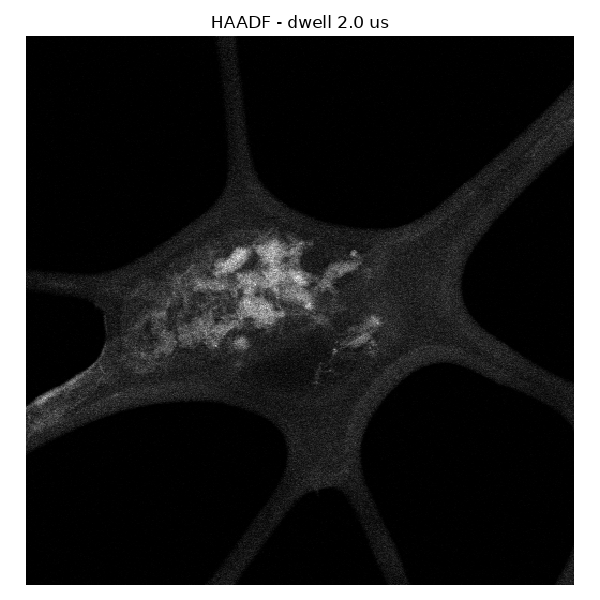

In [25]:
## get HAAADF
data_key = microscope.acquire_scanned_image(["haadf"])

image = client[data_key]["image"]["HAADF"].read()
metadata = dict(client[data_key]["image"]["HAADF"].metadata)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray", interpolation="none")
ax.set_title(f"HAADF - dwell {scan.dwell_time * 1e6:.1f} us")
ax.axis("off")
plt.tight_layout()

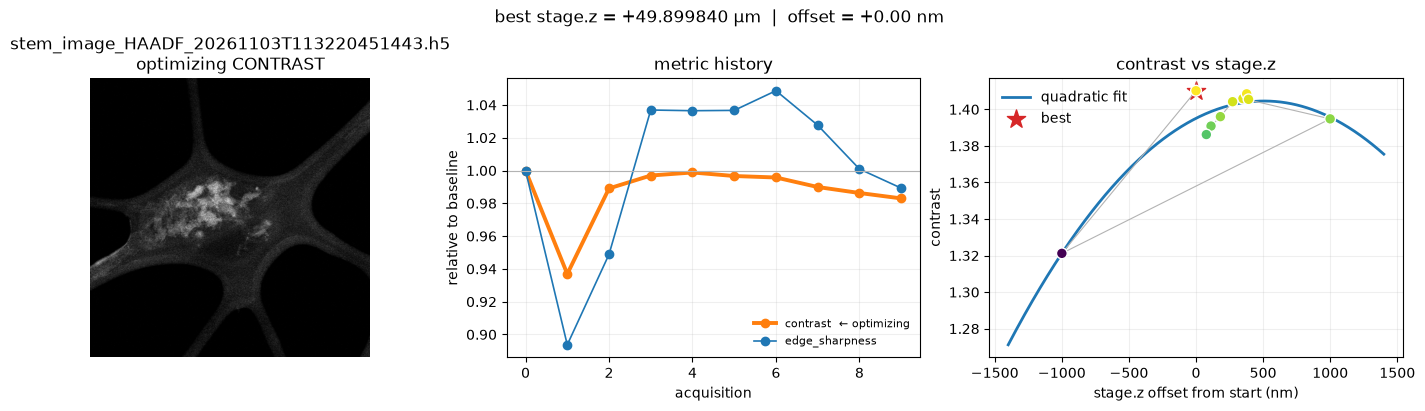

Stage Z complete; optimized contrast: 1.41019
contrast=1.41019, edge_sharpness=0.380412
start=+49.899840 µm, final=+49.899840 µm, offset=+0.000 nm


In [26]:
## Z height tuning
Z_STEP_SIZE = 1e-6  # meters; adjust this first
Z_MAX_ITERATIONS = 50
MAX_Z_OFFSET = 20e-6  # meters from the starting position; hard safety limit

stage_z_result = hill_climb_stage_z(
    Z_STEP_SIZE,
    max_iterations=Z_MAX_ITERATIONS,
    max_offset_m=MAX_Z_OFFSET,
)

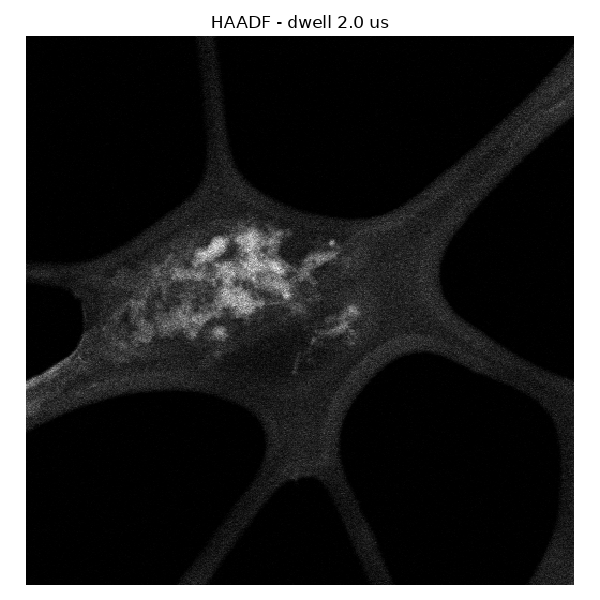

In [27]:
## get HAAADF
data_key = microscope.acquire_scanned_image(["haadf"])

image = client[data_key]["image"]["HAADF"].read()
metadata = dict(client[data_key]["image"]["HAADF"].metadata)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray", interpolation="none")
ax.set_title(f"HAADF - dwell {scan.dwell_time * 1e6:.1f} us")
ax.axis("off")
plt.tight_layout()

In [28]:
# set FOV to higher value for defocus tuning
microscope.set_fov(186e-9)

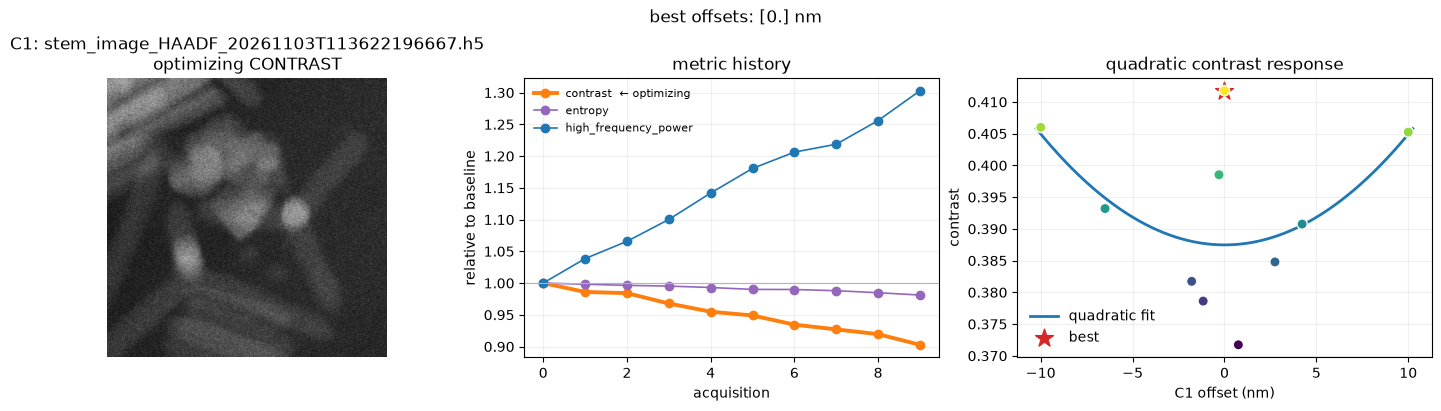

C1 complete; optimized contrast: 0.411764
contrast=0.411764, entropy=0.939474, high_frequency_power=0.193838
offsets=[0.] nm, final trust radius=0.4902 nm


In [32]:
## C1 tuning
C1_STEP_SIZE = 10e-9  # meters; adjust this first
C1_MAX_ITERATIONS = 8

c1_result = hill_climb_aberration(
    "C1", C1_STEP_SIZE, components=1, max_iterations=C1_MAX_ITERATIONS
)

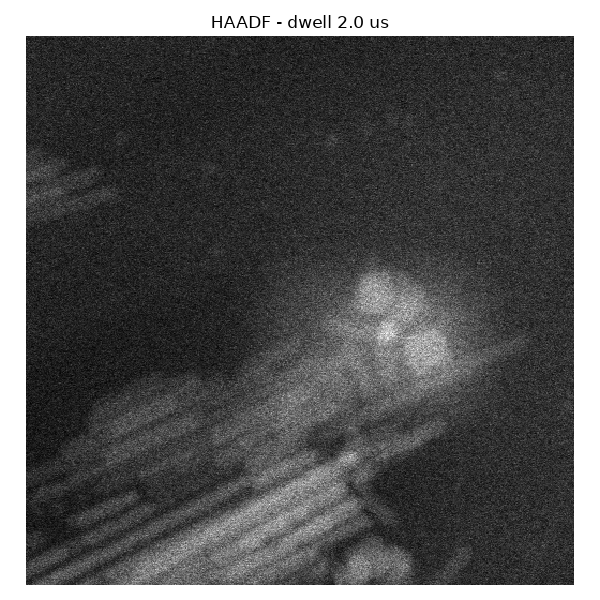

In [31]:
## get HAAADF
data_key = microscope.acquire_scanned_image(["haadf"])

image = client[data_key]["image"]["HAADF"].read()
metadata = dict(client[data_key]["image"]["HAADF"].metadata)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray", interpolation="none")
ax.set_title(f"HAADF - dwell {scan.dwell_time * 1e6:.1f} us")
ax.axis("off")
plt.tight_layout()

In [ ]:





## A1 tuning
A1_STEP_SIZE = 2e-9  # meters; adjust this first
A1_MAX_ITERATIONS = 8

a1_result = hill_climb_aberration(
    "A1", A1_STEP_SIZE, components=2, max_iterations=A1_MAX_ITERATIONS
)

# ## B2 tuning
# B2_STEP_SIZE = 25e-9  # meters; adjust this first
# B2_MAX_ITERATIONS = 8

# b2_result = hill_climb_aberration(
#     "B2", B2_STEP_SIZE, components=2, max_iterations=B2_MAX_ITERATIONS
# )

# ## A2 tuning
# A2_STEP_SIZE = 25e-9  # meters; adjust this first
# A2_MAX_ITERATIONS = 8

# a2_result = hill_climb_aberration(
#     "A2", A2_STEP_SIZE, components=2, max_iterations=A2_MAX_ITERATIONS
# )






In [ ]:
## get HAAADF
data_key = microscope.acquire_scanned_image(["haadf"])

image = client[data_key]["image"]["HAADF"].read()
metadata = dict(client[data_key]["image"]["HAADF"].metadata)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray", interpolation="none")
ax.set_title(f"HAADF - dwell {scan.dwell_time * 1e6:.1f} us")
ax.axis("off")
plt.tight_layout()

In [ ]:
## segmentation
### run segmentation pytango device based on --> notebooks/06_Segmentation.ipynb
seg = tango.DeviceProxy("asyncroscopy/segment/default")
seg.set_timeout_millis(240_000)
results = seg.segment(data_key)
mask = client[results].read()
plt.figure()
plt.imshow(mask)


In [ ]:

## get EDS
key = microscope.acquire_spectrum("eds")
node = client[key]["spectrum"]
spectrum = np.squeeze(np.asarray(node.read()))
metadata = dict(node.metadata)

print("Tiled key     :", key)
print("Metadata      :", metadata)
print("Spectrum shape:", spectrum.shape)
print("Spectrum dtype:", spectrum.dtype)

plt.figure(figsize=(8, 4))
plt.plot(spectrum)
plt.xlabel("Channel")
plt.ylabel("Counts")
plt.title("EDS spectrum")
plt.tight_layout()

## Acquire EDX at particles - skimage

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology

# ---- 1. HAADF ---------------------------------------------------------------
data_key = microscope.acquire_scanned_image(["haadf"])
image = client[data_key]["image"]["HAADF"].read()

In [38]:

# ---- 2. Segmentation --------------------------------------------------------
smooth = filters.gaussian(image.astype(float), sigma=2)
mask = smooth > filters.threshold_otsu(smooth)        # HAADF: particles are bright
mask = morphology.remove_small_objects(ndi.binary_fill_holes(mask), min_size=50)

labels, n = ndi.label(mask)                           # one label per particle
centres = np.array(ndi.center_of_mass(mask, labels, range(1, n + 1)))  # (row, col)
print(f"{n} particles found")


11 particles found


/var/folders/t8/2by8vp4d4dxb7gt4wv0pwbsh0000gn/T/ipykernel_75574/3095152225.py:4: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(ndi.binary_fill_holes(mask), min_size=50)


In [39]:

# ---- 3. EDS at each particle centre -----------------------------------------
def acquire_eds_at(row, col):
    # ASSUMPTION: adapt to your API for parking the beam / defining the scan point.
    # Here: fractional coordinates (0-1) of the HAADF frame.
    h, w = image.shape
    # print(col / w, row / h)
    microscope.place_beam([col / w, row / h])    # <-- replace with your call
    key = microscope.acquire_spectrum("eds")
    return np.squeeze(np.asarray(client[key]["spectrum"].read()))

spectra = np.array([acquire_eds_at(r, c) for r, c in centres])

In [41]:
spectra

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(11, 4096), dtype=uint32)

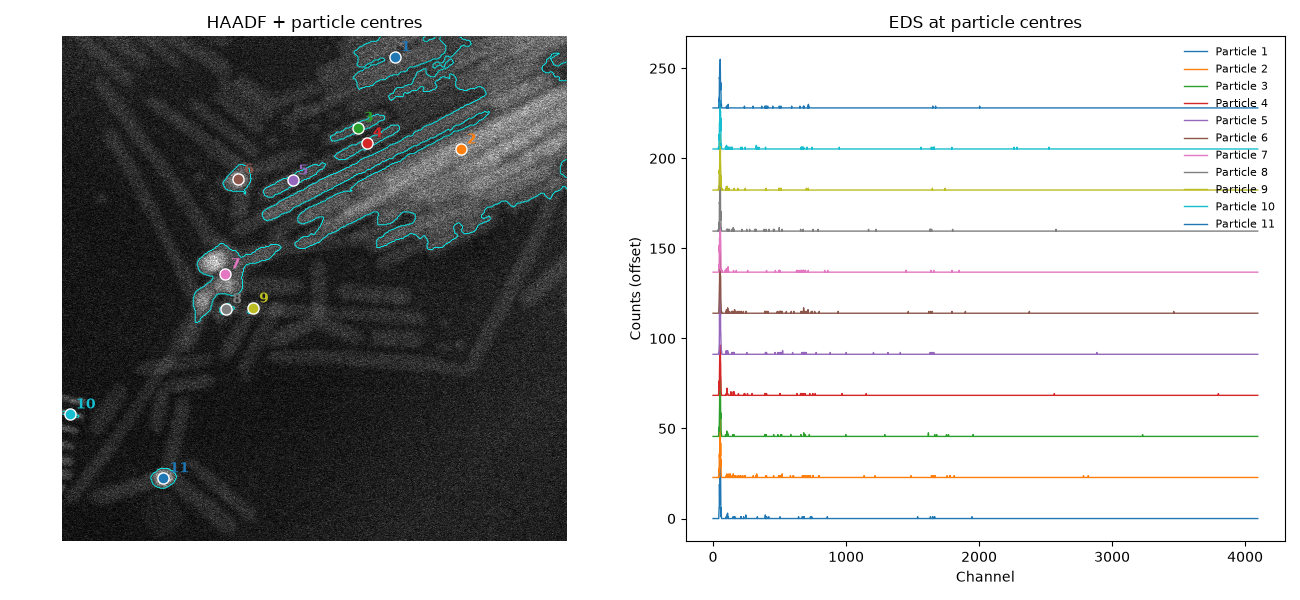

In [40]:
# ---- 4. Plot ----------------------------------------------------------------
fig, (ax_img, ax_eds) = plt.subplots(1, 2, figsize=(13, 6))

ax_img.imshow(image, cmap="gray", interpolation="none")
ax_img.contour(mask, levels=[0.5], colors="cyan", linewidths=0.6)
colors = plt.cm.tab10(np.arange(n) % 10)
for i, (r, c) in enumerate(centres):
    ax_img.plot(c, r, "o", color=colors[i], mec="w", ms=8)
    ax_img.text(c + 6, r - 6, str(i + 1), color=colors[i], weight="bold")
ax_img.set_title("HAADF + particle centres")
ax_img.axis("off")

offset = spectra.max() * 0.6                          # stack spectra vertically
for i, s in enumerate(spectra):
    ax_eds.plot(s + i * offset, color=colors[i], lw=1, label=f"Particle {i + 1}")
ax_eds.set(xlabel="Channel", ylabel="Counts (offset)", title="EDS at particle centres")
ax_eds.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

## Acquire EDX at particles - SAM

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

In [46]:
# import urllib.request
# urllib.request.urlretrieve(
#     "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth",
#     "sam_vit_b_01ec64.pth",
# )

13 particles found


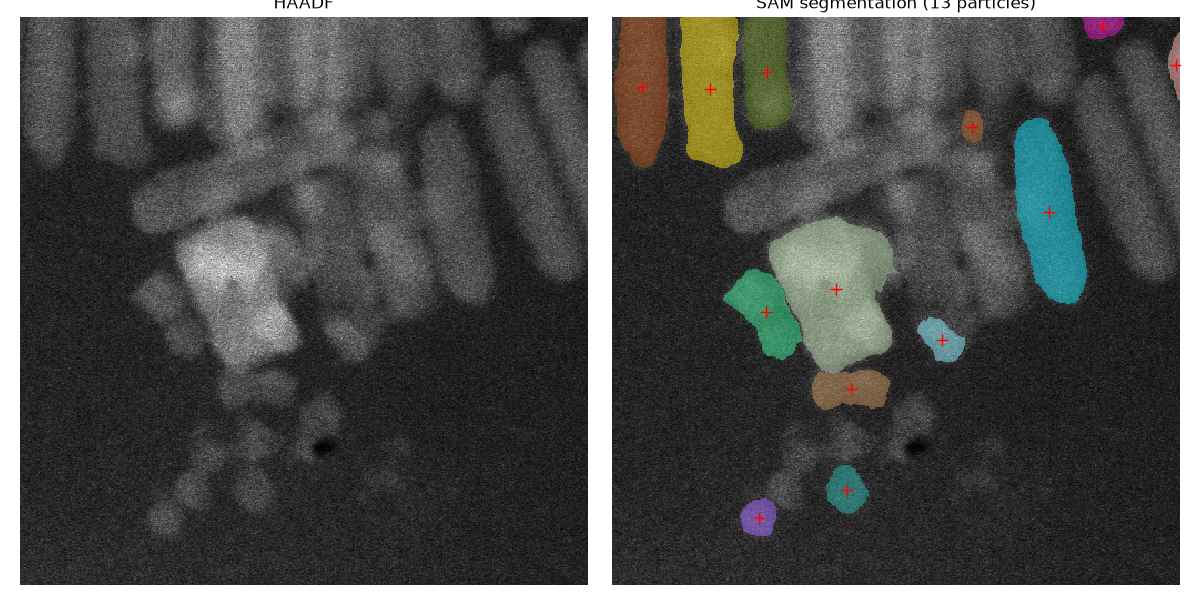

In [48]:
# ---- 1. HAADF ---------------------------------------------------------------
data_key = microscope.acquire_scanned_image(["haadf"])
image = client[data_key]["image"]["HAADF"].read()

# ---- 2. Segmentation --------------------------------------------------------
img8 = ((image - image.min()) / np.ptp(image) * 255).astype(np.uint8)
rgb = np.stack([img8] * 3, -1)                        # SAM expects HxWx3 uint8

device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth").to(device)
generator = SamAutomaticMaskGenerator(
    sam, points_per_side=32, pred_iou_thresh=0.88,
    stability_score_thresh=0.92, min_mask_region_area=50,
)
masks = [m["segmentation"] for m in generator.generate(rgb)]

# drop the background mask(s): too large or darker than the image average
masks = [m for m in masks if m.sum() < 0.25 * m.size and image[m].mean() > image.mean()]

mask = np.any(masks, axis=0)                          # union, used for the plot outline
centres = np.array([ndi.center_of_mass(m) for m in masks])  # (row, col)
n = len(masks)
print(f"{n} particles found")

overlay = np.zeros((*image.shape, 4))
rng = np.random.default_rng(0)
for m in masks:
    overlay[m] = [*rng.random(3), 0.5]

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image, cmap="gray", interpolation="none")
ax[0].set_title("HAADF")
ax[1].imshow(image, cmap="gray", interpolation="none")
ax[1].imshow(overlay, interpolation="none")
ax[1].plot(centres[:, 1], centres[:, 0], "r+", ms=8)
ax[1].set_title(f"SAM segmentation ({n} particles)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

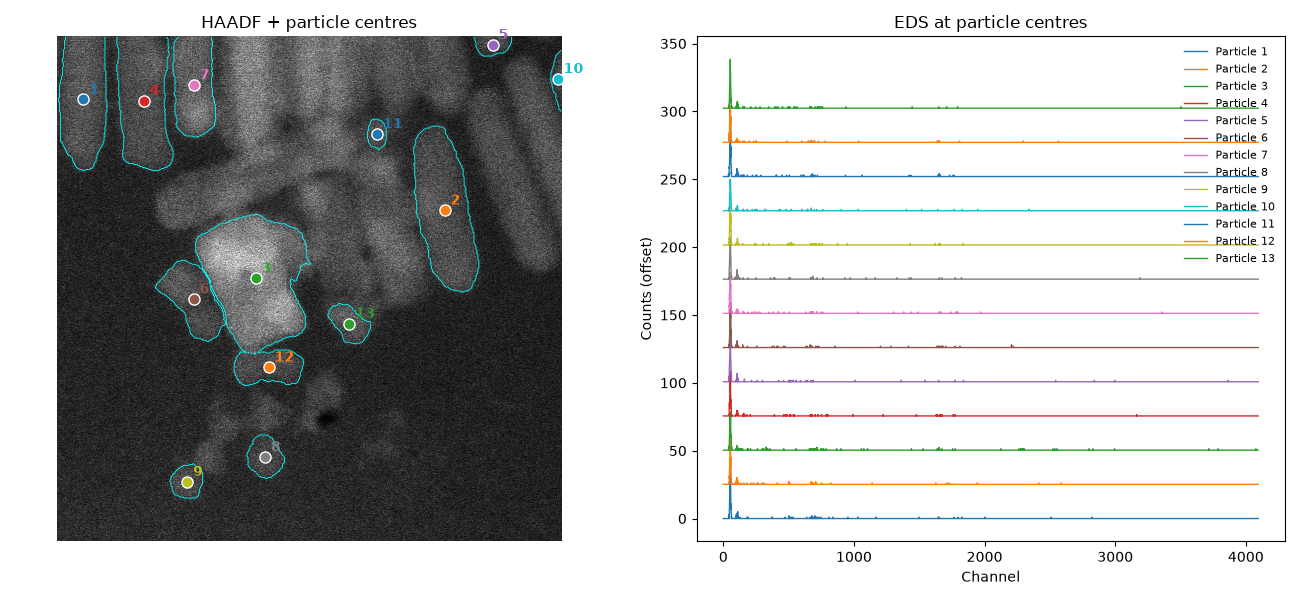

In [49]:
# ---- 3. EDS at each particle centre -----------------------------------------
def acquire_eds_at(row, col):
    # ASSUMPTION: adapt to your API for parking the beam / defining the scan point.
    # Here: fractional coordinates (0-1) of the HAADF frame.
    h, w = image.shape
    microscope.place_beam([col / w, row / h])    # <-- replace with your call
    key = microscope.acquire_spectrum("eds")
    return np.squeeze(np.asarray(client[key]["spectrum"].read()))

spectra = np.array([acquire_eds_at(r, c) for r, c in centres])

# ---- 4. Plot ----------------------------------------------------------------
fig, (ax_img, ax_eds) = plt.subplots(1, 2, figsize=(13, 6))

ax_img.imshow(image, cmap="gray", interpolation="none")
ax_img.contour(mask, levels=[0.5], colors="cyan", linewidths=0.6)
colors = plt.cm.tab10(np.arange(n) % 10)
for i, (r, c) in enumerate(centres):
    ax_img.plot(c, r, "o", color=colors[i], mec="w", ms=8)
    ax_img.text(c + 6, r - 6, str(i + 1), color=colors[i], weight="bold")
ax_img.set_title("HAADF + particle centres")
ax_img.axis("off")

offset = spectra.max() * 0.6                          # stack spectra vertically
for i, s in enumerate(spectra):
    ax_eds.plot(s + i * offset, color=colors[i], lw=1, label=f"Particle {i + 1}")
ax_eds.set(xlabel="Channel", ylabel="Counts (offset)", title="EDS at particle centres")
ax_eds.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()